# Бинарная классификация и метрики

Обучим MLP для бинарной классификации на Breast Cancer. Выберем порог по validation и оценим качество на test с помощью Accuracy, ROC-AUC и матрицы ошибок.


## Ход работы

Загружаем Breast Cancer и выделяем train, validation и test. Обработку пропусков и масштабирование настраиваем только на train, затем применяем к остальным частям. Объединяем обучающие данные в мини-батчи и создаём MLP с одним выходным логитом.

Обучаем сеть с BCEWithLogitsLoss и контролем validation loss, сохраняя лучшие веса. Восстанавливаем выбранную модель и подбираем порог по validation с заданным условием. После этого оцениваем test: выводим Accuracy, ROC-AUC, матрицу ошибок и отчёт по классам. По кривым обучения и отдельным прогнозам разбираем полученное качество.


### Импорты для классификации

Нам понадобятся PyTorch, разделение выборки, нормализация и метрики scikit-learn. Для медицинского учебного набора особенно важны правильная интерпретация классов и исключение утечки данных.

In [1]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import copy
import numpy as np
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

torch.manual_seed(42)


### Загружаем Breast Cancer

Это встроенный датасет с 569 объектами и 30 числовыми признаками. Цель — отличать два класса; в данном наборе класс `0` обозначает malignant, а `1` — benign.

In [2]:

# 1. Загрузка данных
X, y = load_breast_cancer(return_X_y=True)

print("Размер X:", X.shape)
print("Размер y:", y.shape)


Размер X: (569, 30)
Размер y: (569,)


### Выделяем train, validation и test

Сначала откладываем тестовую часть, затем разделяем оставшиеся данные на обучение и валидацию. Тест нельзя использовать для настройки эпохи или порога классификации.

In [3]:

# 2. Разделение на Train, Validation и Test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


Train: 341
Validation: 114
Test: 114


### Обрабатываем признаки без утечки

`SimpleImputer` и `StandardScaler` обучаем только по тренировочным признакам (`fit`). Для validation и test используем лишь `transform`, иначе информация о тестовых данных повлияет на обучение.

In [4]:

# 3. Обработка пропусков и нормализация
prep = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

prep.fit(X_train)

def prepare_x(data):
    scaled = prep.transform(data)
    return torch.tensor(scaled, dtype=torch.float32)

def prepare_y(data):
    return torch.tensor(
        data, dtype=torch.float32
    ).reshape(-1, 1)

train_x = prepare_x(X_train)
val_x = prepare_x(X_val)
test_x = prepare_x(X_test)

train_y = prepare_y(y_train)
val_y = prepare_y(y_val)


### Обучающие мини-батчи

`TensorDataset` объединяет признаки и метки, а `DataLoader` разбивает обучение на партии. В отличие от прежних полных эпох, здесь за одну эпоху выполняется несколько обновлений весов.

In [5]:

# 4. Мини-батчи
train_dataset = TensorDataset(train_x, train_y)

loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)


### Сеть и функция потерь

MLP выдаёт один логит; `BCEWithLogitsLoss` вычисляет бинарную ошибку устойчиво, без отдельного Sigmoid внутри модели. Sigmoid понадобится позже для интерпретации результата как вероятности класса 1.

In [6]:

# 5. Нейросеть
model = nn.Sequential(
    nn.Linear(30, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

loss_fn = nn.BCEWithLogitsLoss()


### Подготавливаем Early Stopping

Запоминаем лучшую валидационную ошибку и место для копии весов. Механизм должен восстановить именно лучший вариант модели, а не оставлять последний после обучающего цикла.

In [7]:

# 6. Early Stopping
best_val_loss = float("inf")
best_epoch = 0
best_weights = None

patience = 20
epochs_without_improvement = 0

train_history = []
val_history = []


### Обучение с контролем валидационной ошибки

В каждой эпохе обновляем веса по train и затем считаем Validation Loss без градиентов. Если ошибка улучшается, сохраняем `state_dict`; иначе увеличиваем счётчик ожидания.

In [8]:

# 7. Цикл обучения
for epoch in range(300):

    model.train()

    for bx, by in loader:
        optimizer.zero_grad()

        prediction = model(bx)
        loss = loss_fn(prediction, by)

        loss.backward()
        optimizer.step()

    # Проверка после каждой эпохи
    model.eval()

    with torch.no_grad():
        train_loss = loss_fn(
            model(train_x), train_y
        ).item()

        val_loss = loss_fn(
            model(val_x), val_y
        ).item()

    train_history.append(train_loss)
    val_history.append(val_loss)

    # Сохранение лучших весов
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(
            model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train: {train_loss:.5f} | "
            f"Val: {val_loss:.5f}"
        )

    if epochs_without_improvement >= patience:
        print("Early Stopping!")
        break


Epoch  10 | Train: 0.37549 | Val: 0.39132
Epoch  20 | Train: 0.19799 | Val: 0.21748
Epoch  30 | Train: 0.13135 | Val: 0.15117
Epoch  40 | Train: 0.09860 | Val: 0.11824
Epoch  50 | Train: 0.07948 | Val: 0.09930
Epoch  60 | Train: 0.06782 | Val: 0.08776
Epoch  70 | Train: 0.06010 | Val: 0.08042


Epoch  80 | Train: 0.05425 | Val: 0.07592
Epoch  90 | Train: 0.04972 | Val: 0.07248
Epoch 100 | Train: 0.04614 | Val: 0.06983
Epoch 110 | Train: 0.04323 | Val: 0.06794
Epoch 120 | Train: 0.04055 | Val: 0.06659
Epoch 130 | Train: 0.03823 | Val: 0.06530
Epoch 140 | Train: 0.03618 | Val: 0.06416


Epoch 150 | Train: 0.03419 | Val: 0.06337
Epoch 160 | Train: 0.03224 | Val: 0.06273
Epoch 170 | Train: 0.03037 | Val: 0.06214
Epoch 180 | Train: 0.02877 | Val: 0.06150
Epoch 190 | Train: 0.02713 | Val: 0.06112
Epoch 200 | Train: 0.02556 | Val: 0.06059
Epoch 210 | Train: 0.02397 | Val: 0.06065


Epoch 220 | Train: 0.02245 | Val: 0.05976
Epoch 230 | Train: 0.02106 | Val: 0.05885
Epoch 240 | Train: 0.01966 | Val: 0.05831
Epoch 250 | Train: 0.01845 | Val: 0.05767
Epoch 260 | Train: 0.01727 | Val: 0.05777
Epoch 270 | Train: 0.01615 | Val: 0.05758
Early Stopping!


### Восстанавливаем лучшую модель и выбираем порог

После обучения возвращаем веса лучшей эпохи. Порог для решения о классе подбираем только по validation с ограничением на полноту класса `0` (malignant), затем фиксируем до проверки на test.

In [9]:

# 8. Восстанавливаем лучшие веса
model.load_state_dict(best_weights)

print("\nЛучшая эпоха:", best_epoch)
print("Лучший Validation Loss:", round(best_val_loss, 5))

from sklearn.metrics import recall_score, precision_score

model.eval()

with torch.no_grad():
    val_probs = torch.sigmoid(
        model(val_x)
    ).numpy().ravel()

best_threshold = 0.5
best_precision = -1

for threshold in np.arange(0.5, 0.96, 0.01):

    val_predictions = (
        val_probs >= threshold
    ).astype(int)

    recall = recall_score(
        y_val,
        val_predictions,
        pos_label=0
    )

    precision = precision_score(
        y_val,
        val_predictions,
        pos_label=0,
        zero_division=0
    )

    # Требуем Recall не меньше 95%
    if recall >= 0.95 and precision > best_precision:
        best_precision = precision
        best_threshold = threshold



Лучшая эпоха: 255
Лучший Validation Loss: 0.05751


### Проверяем, был ли найден допустимый порог

Если ни одно значение порога не удовлетворяет выбранному условию на validation, нельзя молча утверждать, что порог оптимален. Код явно сообщает о такой ситуации.

In [10]:

if best_precision < 0:
    raise RuntimeError("На validation не найден порог с требуемым recall. Пересмотрите условие по validation.")
print("Выбранный порог:", round(best_threshold, 2))


Выбранный порог: 0.5


### Оценка качества на отложенном тесте

На test вычисляем Accuracy и ROC-AUC. Accuracy зависит от порога, ROC-AUC — от упорядочивания вероятностей, поэтому изменение порога может поменять матрицу ошибок без изменения ROC-AUC.

In [11]:

# 9. Проверка на Test
model.eval()

with torch.no_grad():
    logits = model(test_x)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= best_threshold).int()

accuracy = accuracy_score(
    y_test,
    predictions.numpy().ravel()
)

auc = roc_auc_score(
    y_test,
    probabilities.numpy().ravel()
)

print("\nTEST RESULTS")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(auc, 4))



TEST RESULTS
Accuracy: 0.9561
ROC-AUC: 0.9931


### Кривые обучения

Сравниваем Train Loss и Validation Loss по эпохам и отмечаем лучшую эпоху. Рост Validation Loss при падающем Train Loss может указывать на переобучение.

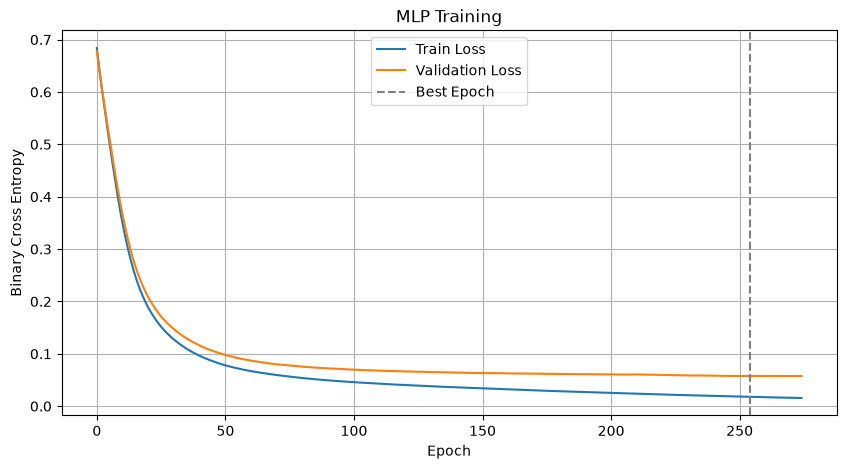

In [12]:

# 10. График обучения
plt.figure(figsize=(10, 5))

plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")

plt.axvline(
    best_epoch - 1,
    color="gray",
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy")
plt.title("MLP Training")
plt.legend()
plt.grid()
plt.show()


### Разбираем конкретные прогнозы

Распечатываем вероятности и ответы нескольких объектов. Порог превращает вероятность в класс, но даже уверенная модель может ошибиться на отдельном примере.


ПРИМЕРЫ ПРЕДСКАЗАНИЙ:
Объект 1: Вероятность класса 1 = 0.000 | Предсказание = 0 | Ответ = 0
Объект 2: Вероятность класса 1 = 1.000 | Предсказание = 1 | Ответ = 1
Объект 3: Вероятность класса 1 = 0.000 | Предсказание = 0 | Ответ = 0
Объект 4: Вероятность класса 1 = 0.320 | Предсказание = 0 | Ответ = 1
Объект 5: Вероятность класса 1 = 0.000 | Предсказание = 0 | Ответ = 0

МАТРИЦА ОШИБОК:
[[41  1]
 [ 4 68]]


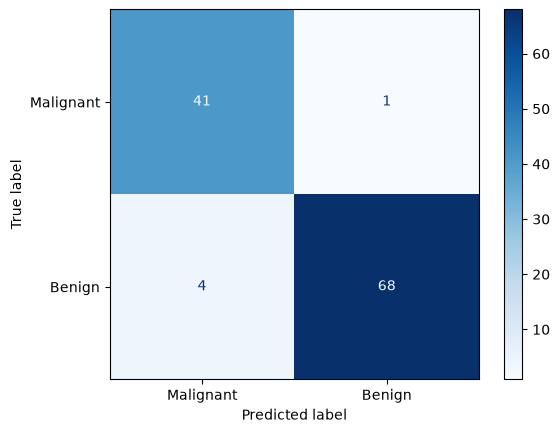

In [13]:

# 11. Несколько примеров предсказаний
print("\nПРИМЕРЫ ПРЕДСКАЗАНИЙ:")

for i in range(5):
    print(
        f"Объект {i + 1}: "
        f"Вероятность класса 1 = "
        f"{probabilities[i].item():.3f} | "
        f"Предсказание = {predictions[i].item()} | "
        f"Ответ = {y_test[i]}"
    )

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    predictions.numpy().ravel()
)

print("\nМАТРИЦА ОШИБОК:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
).plot(cmap="Blues")


### Матрица ошибок и classification report

В матрице различаем правильно и ошибочно предсказанные классы; `precision`, `recall` и `f1-score` дополняют общую Accuracy. Это учебный эксперимент, не диагностическая система.

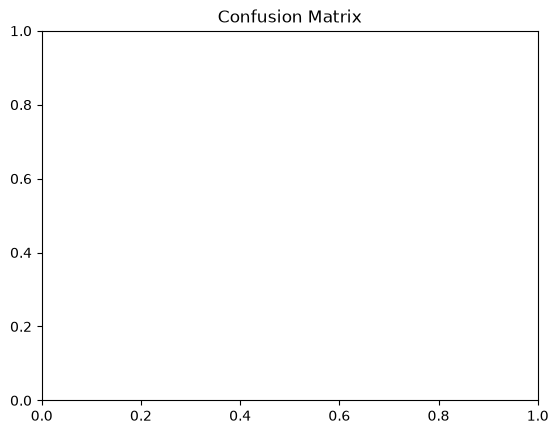


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [14]:

plt.title("Confusion Matrix")
plt.show()

from sklearn.metrics import classification_report

print("\nCLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        predictions.numpy().ravel(),
        target_names=["Malignant", "Benign"]
    )
)

## Выводы

Порог выбираем по validation и затем применяем к test. Accuracy и матрица ошибок показывают результат при этом пороге, а ROC-AUC оценивает ранжирование объектов по вероятности.


## Полный код


Размер X: (569, 30)
Размер y: (569,)
Train: 341
Validation: 114
Test: 114
Epoch  10 | Train: 0.37549 | Val: 0.39132


Epoch  20 | Train: 0.19799 | Val: 0.21748
Epoch  30 | Train: 0.13135 | Val: 0.15117
Epoch  40 | Train: 0.09860 | Val: 0.11824
Epoch  50 | Train: 0.07948 | Val: 0.09930


Epoch  60 | Train: 0.06782 | Val: 0.08776
Epoch  70 | Train: 0.06010 | Val: 0.08042
Epoch  80 | Train: 0.05425 | Val: 0.07592


Epoch  90 | Train: 0.04972 | Val: 0.07248
Epoch 100 | Train: 0.04614 | Val: 0.06983
Epoch 110 | Train: 0.04323 | Val: 0.06794
Epoch 120 | Train: 0.04055 | Val: 0.06659


Epoch 130 | Train: 0.03823 | Val: 0.06530
Epoch 140 | Train: 0.03618 | Val: 0.06416
Epoch 150 | Train: 0.03419 | Val: 0.06337


Epoch 160 | Train: 0.03224 | Val: 0.06273
Epoch 170 | Train: 0.03037 | Val: 0.06214
Epoch 180 | Train: 0.02877 | Val: 0.06150
Epoch 190 | Train: 0.02713 | Val: 0.06112


Epoch 200 | Train: 0.02556 | Val: 0.06059
Epoch 210 | Train: 0.02397 | Val: 0.06065
Epoch 220 | Train: 0.02245 | Val: 0.05976


Epoch 230 | Train: 0.02106 | Val: 0.05885
Epoch 240 | Train: 0.01966 | Val: 0.05831
Epoch 250 | Train: 0.01845 | Val: 0.05767
Epoch 260 | Train: 0.01727 | Val: 0.05777


Epoch 270 | Train: 0.01615 | Val: 0.05758
Early Stopping!

Лучшая эпоха: 255
Лучший Validation Loss: 0.05751


Выбранный порог: 0.5

TEST RESULTS
Accuracy: 0.9561
ROC-AUC: 0.9931


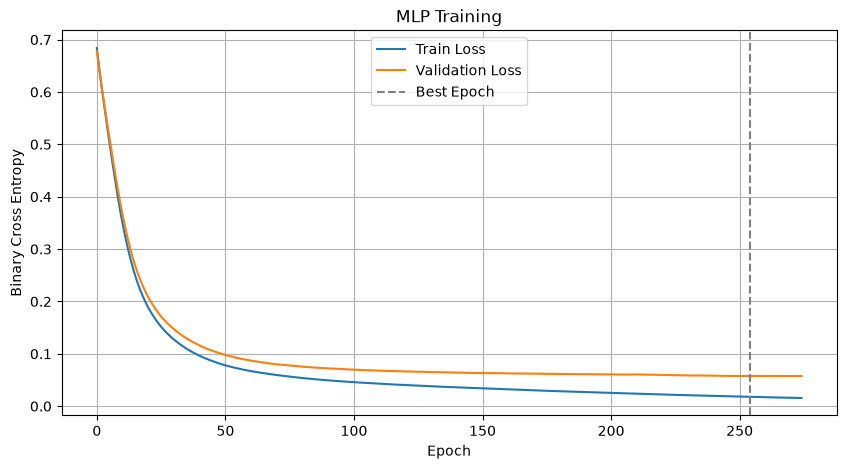


ПРИМЕРЫ ПРЕДСКАЗАНИЙ:
Объект 1: Вероятность класса 1 = 0.000 | Предсказание = 0 | Ответ = 0
Объект 2: Вероятность класса 1 = 1.000 | Предсказание = 1 | Ответ = 1
Объект 3: Вероятность класса 1 = 0.000 | Предсказание = 0 | Ответ = 0
Объект 4: Вероятность класса 1 = 0.320 | Предсказание = 0 | Ответ = 1
Объект 5: Вероятность класса 1 = 0.000 | Предсказание = 0 | Ответ = 0

МАТРИЦА ОШИБОК:
[[41  1]
 [ 4 68]]


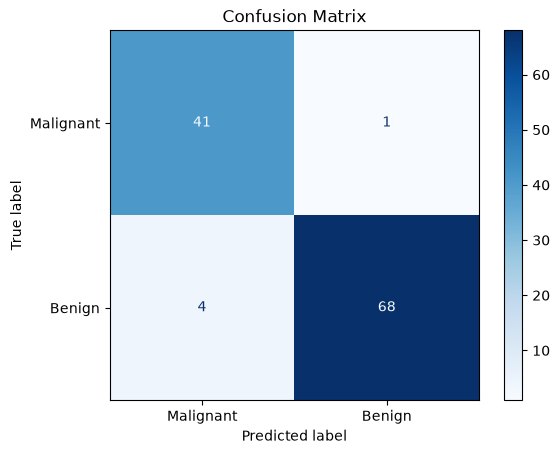


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [15]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import copy
import numpy as np
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

torch.manual_seed(42)

# 1. Загрузка данных
X, y = load_breast_cancer(return_X_y=True)

print("Размер X:", X.shape)
print("Размер y:", y.shape)

# 2. Разделение на Train, Validation и Test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

# 3. Обработка пропусков и нормализация
prep = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

prep.fit(X_train)

def prepare_x(data):
    scaled = prep.transform(data)
    return torch.tensor(scaled, dtype=torch.float32)

def prepare_y(data):
    return torch.tensor(
        data, dtype=torch.float32
    ).reshape(-1, 1)

train_x = prepare_x(X_train)
val_x = prepare_x(X_val)
test_x = prepare_x(X_test)

train_y = prepare_y(y_train)
val_y = prepare_y(y_val)

# 4. Мини-батчи
train_dataset = TensorDataset(train_x, train_y)

loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# 5. Нейросеть
model = nn.Sequential(
    nn.Linear(30, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

loss_fn = nn.BCEWithLogitsLoss()

# 6. Early Stopping
best_val_loss = float("inf")
best_epoch = 0
best_weights = None

patience = 20
epochs_without_improvement = 0

train_history = []
val_history = []

# 7. Цикл обучения
for epoch in range(300):

    model.train()

    for bx, by in loader:
        optimizer.zero_grad()

        prediction = model(bx)
        loss = loss_fn(prediction, by)

        loss.backward()
        optimizer.step()

    # Проверка после каждой эпохи
    model.eval()

    with torch.no_grad():
        train_loss = loss_fn(
            model(train_x), train_y
        ).item()

        val_loss = loss_fn(
            model(val_x), val_y
        ).item()

    train_history.append(train_loss)
    val_history.append(val_loss)

    # Сохранение лучших весов
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(
            model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train: {train_loss:.5f} | "
            f"Val: {val_loss:.5f}"
        )

    if epochs_without_improvement >= patience:
        print("Early Stopping!")
        break

# 8. Восстанавливаем лучшие веса
model.load_state_dict(best_weights)

print("\nЛучшая эпоха:", best_epoch)
print("Лучший Validation Loss:", round(best_val_loss, 5))

from sklearn.metrics import recall_score, precision_score

model.eval()

with torch.no_grad():
    val_probs = torch.sigmoid(
        model(val_x)
    ).numpy().ravel()

best_threshold = 0.5
best_precision = -1

for threshold in np.arange(0.5, 0.96, 0.01):

    val_predictions = (
        val_probs >= threshold
    ).astype(int)

    recall = recall_score(
        y_val,
        val_predictions,
        pos_label=0
    )

    precision = precision_score(
        y_val,
        val_predictions,
        pos_label=0,
        zero_division=0
    )

    # Требуем Recall не меньше 95%
    if recall >= 0.95 and precision > best_precision:
        best_precision = precision
        best_threshold = threshold

if best_precision < 0:
    raise RuntimeError("На validation не найден порог с требуемым recall. Пересмотрите условие по validation.")
print("Выбранный порог:", round(best_threshold, 2))

# 9. Проверка на Test
model.eval()

with torch.no_grad():
    logits = model(test_x)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= best_threshold).int()

accuracy = accuracy_score(
    y_test,
    predictions.numpy().ravel()
)

auc = roc_auc_score(
    y_test,
    probabilities.numpy().ravel()
)

print("\nTEST RESULTS")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(auc, 4))

# 10. График обучения
plt.figure(figsize=(10, 5))

plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")

plt.axvline(
    best_epoch - 1,
    color="gray",
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy")
plt.title("MLP Training")
plt.legend()
plt.grid()
plt.show()

# 11. Несколько примеров предсказаний
print("\nПРИМЕРЫ ПРЕДСКАЗАНИЙ:")

for i in range(5):
    print(
        f"Объект {i + 1}: "
        f"Вероятность класса 1 = "
        f"{probabilities[i].item():.3f} | "
        f"Предсказание = {predictions[i].item()} | "
        f"Ответ = {y_test[i]}"
    )

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    predictions.numpy().ravel()
)

print("\nМАТРИЦА ОШИБОК:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

from sklearn.metrics import classification_report

print("\nCLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        predictions.numpy().ravel(),
        target_names=["Malignant", "Benign"]
    )
)